# 03 - One-star walkthrough

Exploration only: try the pipeline on two TCEs and look at the plots.
The real logic lives in `src/preprocess.py`; this notebook just imports it.

In [26]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
# A notebook runs from notebooks/, so add the repo root to Python's path.
sys.path.insert(0, str(Path.cwd().parent))

from src.config import GLOBAL_BINS, PROCESSED_DIR, PROCESSED_FILE
from src.preprocess import fold_tce, load_light_curve

In [27]:
tce_data = pd.read_csv(PROCESSED_DIR / PROCESSED_FILE)
print(tce_data.shape)
print(tce_data["label"].value_counts())
raw = load_light_curve(2019477)
raw.plot();

(15737, 7)
label
0    12137
1     3600
Name: count, dtype: int64


## Raw light curve (KIC 757450, a planet candidate)

In [ ]:
raw = load_light_curve(2019477)
raw.plot();

## Folded: planet candidate vs. false positive

- KIC 1161345, planet 1: PC, period about 4.2 d
- KIC 1162345, planet 2: AFP, period about 0.83 d

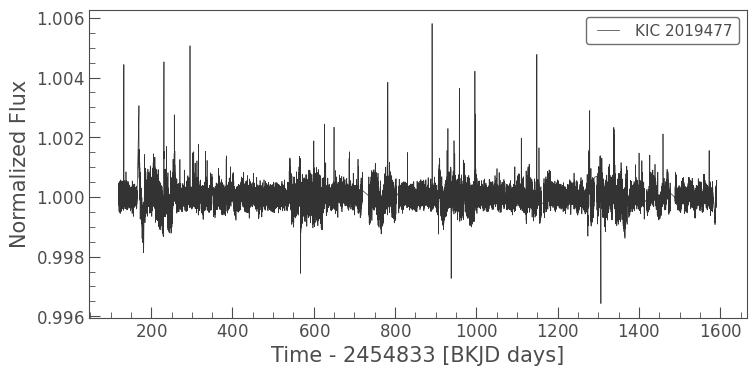

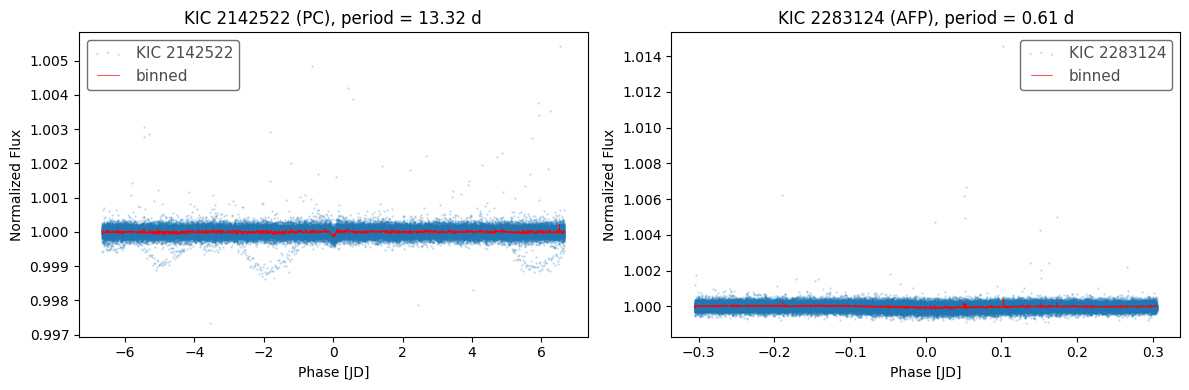

In [28]:
def get_tce(kepid, plnt_num):
    return tce_data[(tce_data.kepid == kepid) & (tce_data.tce_plnt_num == plnt_num)].iloc[0]

candidate = get_tce(2142522, 1)
false_positive = get_tce(2283124, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tce, name in [(axes[0], candidate, "PC"), (axes[1], false_positive, "AFP")]:
    folded, duration_days = fold_tce(tce)
    folded.scatter(ax=ax, s=1, alpha=0.3)
    folded.bin(bins=GLOBAL_BINS).plot(ax=ax, color="red", label="binned")
    ax.set_title(f"KIC {int(tce.kepid)} ({name}), period = {tce.tce_period:.2f} d")
plt.tight_layout()
plt.show()

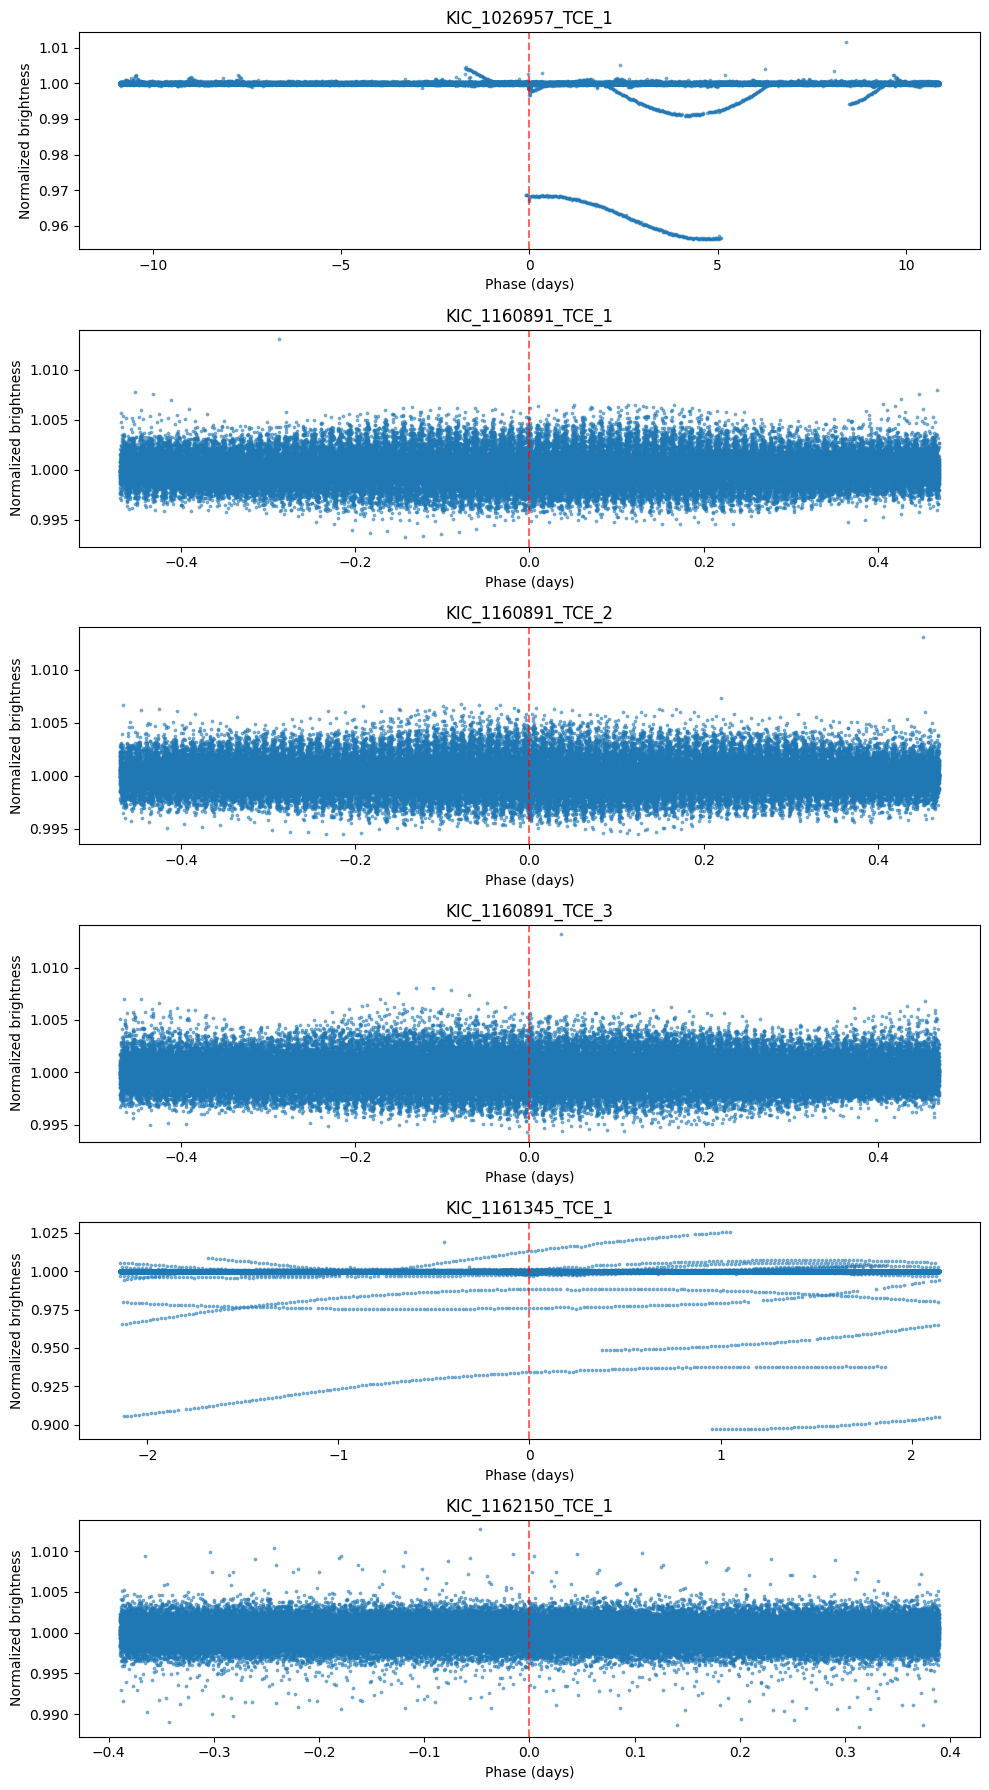

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.config import FOLDED_LIGHT_CURVE_DIR
# Grab the first 6 processed TCEs
files = sorted(FOLDED_LIGHT_CURVE_DIR.glob("KIC_*_TCE_*.fits"))[:6]

fig, axes = plt.subplots(len(files), 1, figsize=(10, 3 * len(files)))

if len(files) == 1:
    axes = [axes]

for ax, path in zip(axes, files):
    folded = lk.read(path)

    ax.scatter(
        folded.time.value,
        folded.flux.value,
        s=3,
        alpha=0.5
    )

    ax.axvline(0, color="red", linestyle="--", alpha=0.6)
    ax.set_title(path.stem)
    ax.set_xlabel("Phase (days)")
    ax.set_ylabel("Normalized brightness")

plt.tight_layout()
plt.show()

In [13]:
import json

metadata_path = FOLDED_LIGHT_CURVE_DIR / "KIC_1161345_TCE_1.json"

with open(metadata_path) as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=4))

{
    "kepid": 1161345,
    "tce_plnt_num": 1,
    "period_days": 4.28758,
    "epoch_bkjd": 133.434,
    "duration_days": 0.046375,
    "mask_width_factor": 1.5,
    "lightkurve_version": "2.6.0"
}


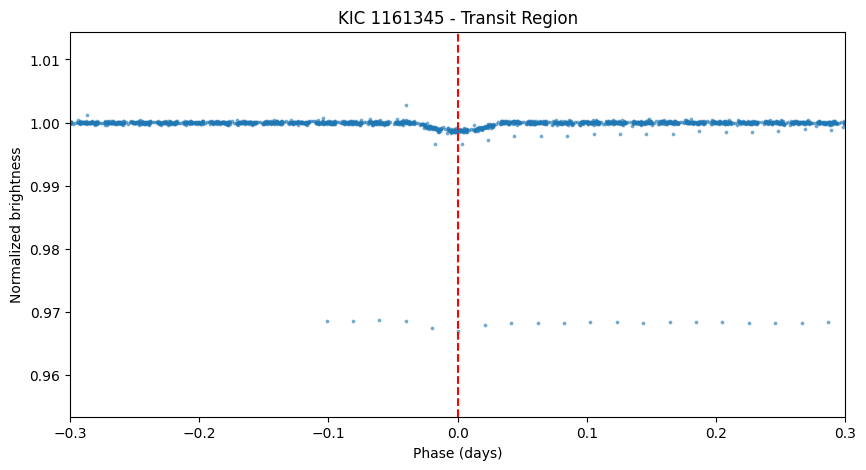

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    folded.time.value,
    folded.flux.value,
    s=3,
    alpha=0.5
)

plt.xlim(-0.3, 0.3)
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Phase (days)")
plt.ylabel("Normalized brightness")
plt.title("KIC 1161345 - Transit Region")
plt.show()

In [10]:
import numpy as np

transit_times = epoch + np.arange(
    0,
    int((original.time.value.max() - epoch) / period) + 1
) * period

print("Predicted transit times:")
print(transit_times)

Predicted transit times:
[ 144.779   166.5403  188.3016  210.0629  231.8242  253.5855  275.3468
  297.1081  318.8694  340.6307  362.392   384.1533  405.9146  427.6759
  449.4372  471.1985  492.9598  514.7211  536.4824  558.2437  580.005
  601.7663  623.5276  645.2889  667.0502  688.8115  710.5728  732.3341
  754.0954  775.8567  797.618   819.3793  841.1406  862.9019  884.6632
  906.4245  928.1858  949.9471  971.7084  993.4697 1015.231  1036.9923
 1058.7536 1080.5149 1102.2762 1124.0375 1145.7988 1167.5601 1189.3214
 1211.0827 1232.844  1254.6053 1276.3666 1298.1279 1319.8892 1341.6505
 1363.4118 1385.1731 1406.9344 1428.6957 1450.457  1472.2183 1493.9796
 1515.7409 1537.5022 1559.2635 1581.0248]


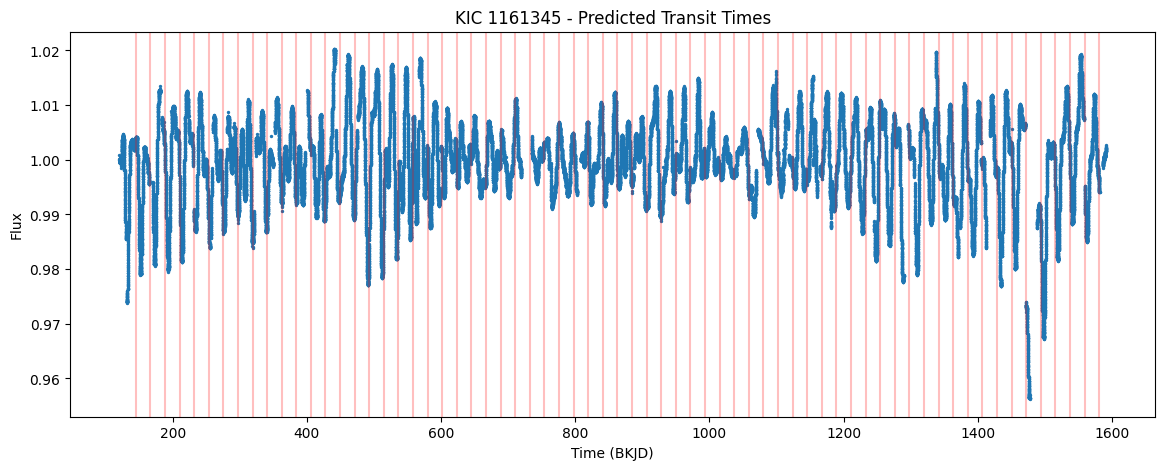

In [15]:
transit_times = epoch + np.arange(
    0,
    int((original.time.value.max() - epoch) / period) + 1
) * period

plt.figure(figsize=(14, 5))
plt.scatter(original.time.value, original.flux.value, s=2)

for t in transit_times:
    plt.axvline(t, color="red", alpha=0.25)

plt.xlabel("Time (BKJD)")
plt.ylabel("Flux")
plt.title("KIC 1161345 - Predicted Transit Times")
plt.show()